In [6]:
import numpy as np
import matplotlib.pyplot as plt

<h3> Exercise 2.4, Part b) </h3>

In [7]:
def explicit_euler(t0, x0, f, b, h):
    N = int(round((b - t0) / h))
    t = t0 + h * np.arange(N + 1)
    m = len(x0)
    x = np.empty((m, N + 1))
    x[:, 0] = x0
    for n in range(N):
        x[:, n + 1] = x[:, n] + h * f(t[n], x[:, n])
    return t, x

In [8]:
def implicit_euler(t0, x0, b, A, h):
    N = int(round((b-t0)/h))
    t = t0 + h * np.arange(N + 1)
    m = len(x0)
    I =np.eye(m)
    x = np.empty((m, N+1))
    x[:, 0] =x0
    C = np.linalg.inv(I - h*A)
    for n in range(1, N+1):
        x[:, n] = C @ x[:, n-1]
    return t, x

In [9]:
A = np.array([[0, 1],
             [-1, 0]])

x0 = np.array([1, 0])

f = lambda t, x,: A @ x

h =0.01

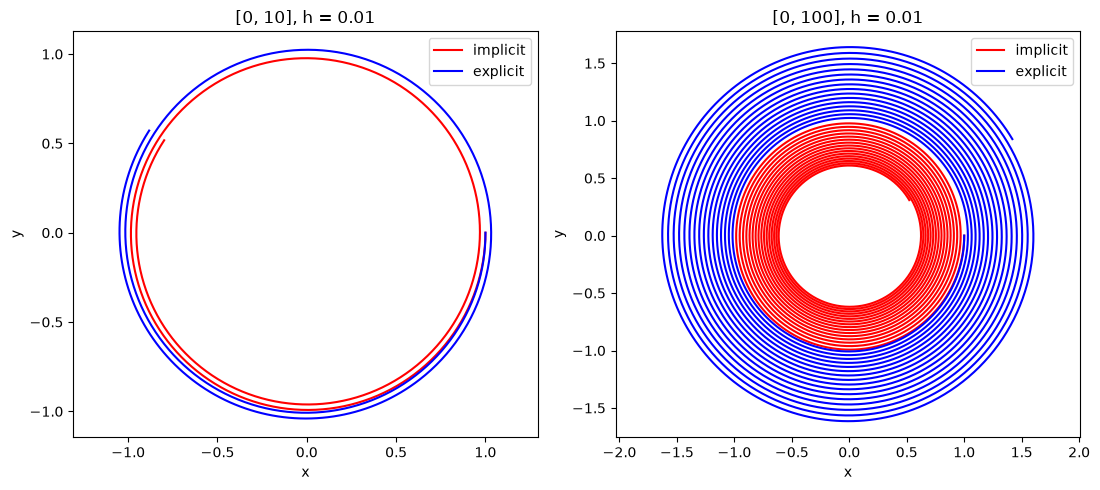

In [10]:
fig, axs =plt.subplots(1, 2, figsize=(11, 5))
for ax, b in zip(axs, [10, 100]):
    t_i, x_i = implicit_euler(0, x0, b, A, h)
    t_e, x_e = explicit_euler(0, x0, f, b, h)
    ax.plot(x_i[0,:], x_i[1, :], label='implicit', color='red')
    ax.plot(x_e[0,:], x_e[1, :], label='explicit', color='blue')
    ax.set_title(f'[0, {b}], h = {h}')
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.axis('equal'); ax.legend()
plt.tight_layout()
plt.show()